## **1.2 Mempelajari Penggunaan Driver Neo4J**

In [1]:
from neo4j import GraphDatabase, RoutingControl

# Konfigurasi Koneksi Database
URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "Frelin_27")  

# Fungsi buat nambah data node & relasi
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name,
        friend_name=friend_name,
        database_="neo4j",
    )


# Fungsi buat nampilin daftar teman
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name,
        database_="neo4j",
        routing_=RoutingControl.READ,
    )
    print(f"Daftar teman {name}:")
    for record in records:
        print(f"- {record['friend.name']}")


# Eksekusi Program
if __name__ == "__main__":
    with GraphDatabase.driver(URI, auth=AUTH) as driver:
        # Tambah relasi pertemanan
        add_friend(driver, "Arthur", "Guinevere")
        add_friend(driver, "Arthur", "Lancelot")
        add_friend(driver, "Arthur", "Merlin")

        # Cetak hasil
        print_friends(driver, "Arthur")

Daftar teman Arthur:
- Guinevere
- Lancelot
- Merlin


1. Apa nama database yang digunakan pada tutorial ini? 

database yang digunakan pada tutorial ini adalah neo4j. Hal ini terlihat langsung dari penulisan parameter database_="neo4j" di dalam fungsi add_friend maupun print_friends pada skrip Python, yang merupakan nama database bawaan (default) pada instance Neo4j

2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance! 

cara mengakses atau berpindah ke database lain dalam satu instance bisa dilakukan melalui kode Python dengan mengganti nilai parameter database_ sesuai nama database tujuan. Jika dari sisi sintaks Cypher, kita dapat menambahkan klausa USE <nama_database> pada awal baris kueri agar eksekusinya langsung mengarah ke database tersebut. Selain itu, terdapat perintah administrasi pendukung seperti SHOW DATABASES untuk melihat daftar database yang ada, CREATE DATABASE dan DROP DATABASE untuk membuat atau menghapus database, serta START DATABASE dan STOP DATABASE untuk mengaktifkan atau mematikan database tertentu.

3. Apa jenis graf pertemanan yang telah dibuat di sini? 


jenis graf pertemanan yang dibentuk adalah Graf Berarah Homogen (Directed Homogeneous Graph). Graf ini dikategorikan homogen karena seluruh simpul (node) hanya menggunakan satu jenis label entitas saja, yaitu :Person. Graf ini juga bersifat berarah (directed) karena relasinya didefinisikan spesifik satu arah melalui pola panah (a)-[:KNOWS]->(friend), sehingga hubungan pertemanan mengalir dari Arthur ke temannya dan tidak otomatis berlaku sebaliknya

# **2.1 Wrangling dan EDA**

## **1. Inisialisasi Environment & Koneksi**

Mengimpor seluruh library pendukung (Pandas, NumPy, SciPy, Scikit-Learn, NetworkX, dan Driver Neo4j) serta mengecek koneksi ke database.

In [2]:
import os
import math
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from neo4j import GraphDatabase

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "Frelin_27")

try:
    driver = GraphDatabase.driver(URI, auth=AUTH)
    driver.verify_connectivity()
    print("berhasil terhubung ke Neo4j Database!")
except Exception as e:
    print(f"gagal terhubung ke Neo4j: {e}")

berhasil terhubung ke Neo4j Database!


## **2. Split Dataset (Training P1 & Testing P2)**

Di sini kita membagi file utama jadi dua masa. Data P1 (periode awal) bakal dipakai buat ngebangun graf dan nyari rekomendasi. Sedangkan data P2 (periode setelahnya) kita simpan dulu di luar Neo4j, fungsinya cuma buat kunci jawaban pas mau ngecek apakah tebakan rekomendasi dari graf kita di P1 itu terbukti benar dibuka sama user di P2.



In [3]:
# 1. Baca data awal
df = pd.read_csv("events_filtered.csv")

# 2. Ubah format timestamp ke bentuk tanggal/waktu
df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")

# 3. Potong data sesuai rentang tanggal resmi Frelin:
p1_start, p1_end = "2015-06-01", "2015-08-11"
p2_start, p2_end = "2015-08-11", "2015-08-29"

df_p1 = df[(df["timestamp"] >= p1_start) & (df["timestamp"] < p1_end)]
df_p2 = df[(df["timestamp"] >= p2_start) & (df["timestamp"] < p2_end)]

# 4. Simpan masing-masing jadi file CSV baru
df_p1.to_csv("events_p1.csv", index=False)
df_p2.to_csv("events_p2.csv", index=False)

print(f"Data P1 (Training) Frelin : {len(df_p1)} baris -> disimpan ke events_p1.csv")
print(f"Data P2 (Testing) Frelin  : {len(df_p2)} baris -> disimpan ke events_p2.csv")

Data P1 (Training) Frelin : 1486039 baris -> disimpan ke events_p1.csv
Data P2 (Testing) Frelin  : 325830 baris -> disimpan ke events_p2.csv


## **3. Import P1 ke Neo4j & Cek Komposisi Node (Menjawab Soal No. 3)**

disini data yang dimasukkan hanya data P1 ke Neo4j. Kueri cypher memerintahkan database untuk membuat simpul Visitor dan Item, lalu dihubungkan dengan garis VIEWED. Setelah dihitung jumlahnya, bisa dilihat kalau graf yang terbentuk adalah  graf dua kelompok (bipartite graph)

In [4]:
import math
import pandas as pd
from neo4j import GraphDatabase
from tqdm import tqdm

csv_file_path = "events_p1.csv"
batch_size = 10000 
# 1. Optimasi Fungsi Import Batch (Tanpa CALL & Relasi Pakai CREATE)
def import_batch(tx, batch):
    query = """
    UNWIND $batch AS row

    // MERGE tetap dipakai untuk Node agar Visitor & Item tidak duplikat
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    // FOREACH jauh lebih cepat dari CALL subquery
    FOREACH (_ IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
        CREATE (v)-[:VIEWED {timestamp: row.timestamp, eventId: row.event_id}]->(i)
    )

    FOREACH (_ IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp, eventId: row.event_id}]->(i)
    )

    FOREACH (_ IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, eventId: row.event_id, transactionId: row.transactionid}]->(i)
    )
    """
    tx.run(query, batch=batch)

print("Fungsi import_batch siap digunakan.")

# 2. Buat Constraint Unique Index
driver.execute_query(
    """
    CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
    FOR (v:Visitor)
    REQUIRE v.visitorId IS UNIQUE
    """
)

driver.execute_query(
    """
    CREATE CONSTRAINT item_id_unique IF NOT EXISTS
    FOR (i:Item)
    REQUIRE i.itemId IS UNIQUE
    """
)

# 3. Hitung Total Baris File P1 untuk Progress Bar
total_rows = sum(1 for _ in open(csv_file_path)) - 1
total_chunks = math.ceil(total_rows / batch_size)

# 4. Eksekusi Import per Chunk (Batch)
with driver.session() as session:
    for chunk in tqdm(
        pd.read_csv(
            csv_file_path,
            chunksize=batch_size,
            dtype={"transactionid": "string"}
        ),
        total=total_chunks,
        desc="Mengimpor data P1"
    ):
        chunk["event_id"] = chunk.index.astype(str)
        chunk["visitorid"] = chunk["visitorid"].astype("int64")
        chunk["itemid"] = chunk["itemid"].astype("int64")
        chunk["timestamp"] = pd.to_datetime(chunk["timestamp"]).astype("int64") // 10**6
        chunk["transactionid"] = chunk["transactionid"].fillna("")

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Proses impor data P1 selesai.")

Fungsi import_batch siap digunakan.


Mengimpor data P1: 100%|██████████| 149/149 [01:50<00:00,  1.35it/s]

Proses impor data P1 selesai.


In [12]:
# Cek Komposisi Node & Relasi di Neo4j (Soal No. 3)
with driver.session() as session:
    res_visitor = session.run("MATCH (v:Visitor) RETURN count(v) AS total").single()
    res_item = session.run("MATCH (i:Item) RETURN count(i) AS total").single()
    res_rel = session.run("MATCH ()-[r]->() RETURN count(r) AS total").single()

    total_visitor = res_visitor["total"]
    total_item = res_item["total"]
    total_relasi = res_rel["total"]

print("--- HASIL CEK KOMPOSISI NODE & RELASI (SOAL NO. 3) ---")
print(f"Total Node Visitor : {total_visitor}")
print(f"Total Node Item    : {total_item}")
print(f"Total Relasi       : {total_relasi}")
print("Jenis Graf         : Bipartite Graph (Visitor -> Item)")

--- HASIL CEK KOMPOSISI NODE & RELASI (SOAL NO. 3) ---
Total Node Visitor : 770014
Total Node Item    : 180134
Total Relasi       : 1486047
Jenis Graf         : Bipartite Graph (Visitor -> Item)


## **4. Vector Space Modelling (VSM) Node User (Menjawab Soal No. 4)**

Visualisasi sampel *subgraph* menggambarkan *Bipartite Graph* untuk *Vector Space Modelling* (VSM) berbasis pengguna (*User-centric*). Simpul (*node*) biru mewakili *User*, simpul oranye mewakili *Item*, dan garis abu-abu menunjukkan interaksi di antara keduanya. Struktur jaring-jaring yang renggang (*sparse*) membuktikan bahwa mayoritas nilai matriks VSM *User* bernilai nol karena pengguna umumnya hanya melihat sedikit produk dari total katalog. Selain itu, terlihat perbedaan popularitas produk di mana *Item_309778* dan *Item_461686* menjadi pusat interaksi banyak pengguna, sementara *Item_5411* hanya memiliki satu interaksi.

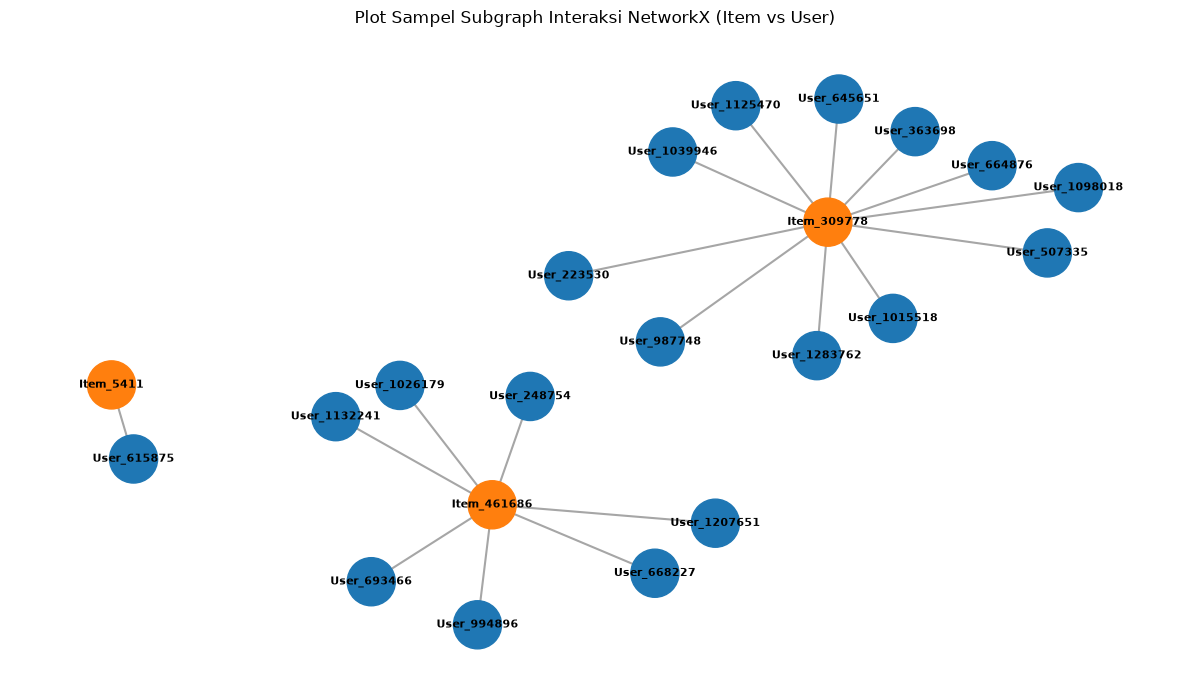

In [5]:
import matplotlib.pyplot as plt
import networkx as nx

# 1. Ambil 5 Item paling populer (paling banyak diinteraksi)
top_5_items = df_p1["itemid"].value_counts().head(5).index

# 2. Ambil sampel interaksi khusus dari Top 5 Item tersebut
df_sample = df_p1[df_p1["itemid"].isin(top_5_items)].head(20)

# 3. Buat Graf Bipartite
G = nx.Graph()
for _, row in df_sample.iterrows():
    u_node = f"User_{row['visitorid']}"
    i_node = f"Item_{row['itemid']}"
    G.add_edge(u_node, i_node)

# 4. Atur warna node: Biru untuk User, Oranye untuk Item
node_colors = [
    "#1f77b4" if node.startswith("User") else "#ff7f0e" for node in G.nodes()
]

# 5. Gambar NetworkX
plt.figure(figsize=(12, 7))
pos = nx.spring_layout(G, k=0.6, seed=42)

nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=1200)
nx.draw_networkx_edges(G, pos, edge_color="gray", alpha=0.7, width=1.5)
nx.draw_networkx_labels(G, pos, font_size=8, font_weight="bold")

plt.title(
    "Plot Sampel Subgraph Interaksi NetworkX (Item vs User)",
    fontsize=12,
    pad=15,
)
plt.axis("off")
plt.tight_layout()

plt.savefig("subgraph_item_vs_user.png", dpi=300, bbox_inches="tight")
plt.show()

## **5. Vector Space Modelling (VSM) Node Item (Menjawab Soal No. 5)**

Visualisasi sampel *subgraph* menggambarkan proyeksi *Vector Space Modelling* (VSM) berbasis produk (*Item-centric*) untuk 5 sampel produk. Simpul (*node*) oranye mewakili produk (*Item*), simpul biru mewakili *User*, dan garis abu-abu menunjukkan interaksi di antara keduanya. Berbeda dengan VSM *User*, proyeksi berbasis *Item* memperlihatkan struktur jaring-jaring yang membentuk kelompok-kelompok (*cluster*) lebih rapat. Hal ini terjadi karena produk populer sering kali dikunjungi secara bersamaan oleh pengguna yang sama, sehingga antar-item terhubung membentuk pola komunitas yang relatif stabil.

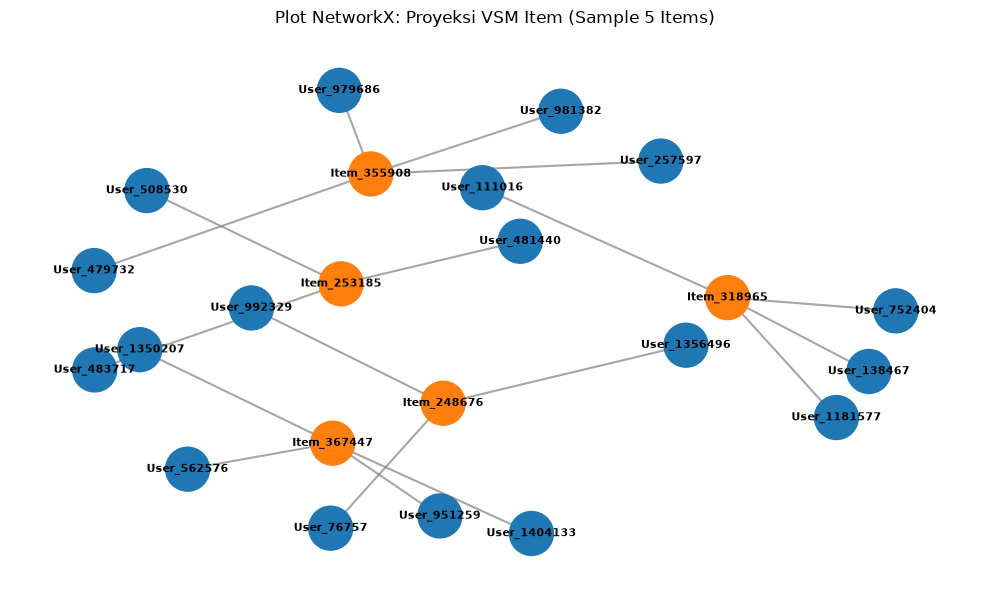

In [6]:
import matplotlib.pyplot as plt
import networkx as nx

# 1. Ambil sampel 5 Item saja
sample_items = df_p1["itemid"].unique()[:5]
df_sample_item = df_p1[df_p1["itemid"].isin(sample_items)]

# 2. Batasi maksimal 4 user per item biar node user-nya nggak membludak & numpuk
df_sample_item = df_sample_item.groupby("itemid").head(4)

# 3. Buat Graf NetworkX
G_item = nx.Graph()
for _, row in df_sample_item.iterrows():
    G_item.add_edge(f"Item_{row['itemid']}", f"User_{row['visitorid']}")

# 4. Atur warna: Item = Oranye, User = Biru
node_colors = [
    "#ff7f0e" if node.startswith("Item") else "#1f77b4" for node in G_item.nodes()
]

# 5. Plot Grafik (k=0.8 bikin jarak antar node jadi lebih renggang)
plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G_item, k=0.8, seed=42)

nx.draw_networkx_nodes(G_item, pos, node_color=node_colors, node_size=1000)
nx.draw_networkx_edges(G_item, pos, edge_color="gray", alpha=0.7, width=1.5)
nx.draw_networkx_labels(G_item, pos, font_size=8, font_weight="bold")

plt.title("Plot NetworkX: Proyeksi VSM Item (Sample 5 Items)", fontsize=12, pad=15)
plt.axis("off")
plt.tight_layout()

plt.savefig("vsm_item_5_sample.png", dpi=300, bbox_inches="tight")
plt.show()

## **6. Analisis Efektivitas & Efisiensi Proyeksi (Menjawab Soal No. 6)**

Proyeksi berbasis produk (Item-centric) jauh lebih efisien dibanding proyeksi berbasis pengguna (User-centric) karena jumlah katalog produk lebih sedikit dan cenderung stabil. Hal ini menghasilkan ukuran matriks kemiripan ($N \times N$) yang jauh lebih kecil dan hemat memori saat diolah dengan Sparse CSR Matrix, sehingga terhindar dari risiko MemoryError.Selain itu, karakteristik produk bersifat statis sehingga matriks kemiripan tidak perlu dihitung ulang setiap saat, berbeda dengan perilaku pengguna yang sangat dinamis. Pada database Neo4j, proyeksi berbasis produk membuat pembentukan relasi :SIMILAR lebih terkontrol, sehingga visualisasi graf menjadi lebih rapi dan kueri Cypher dapat dieksekusi dengan jauh lebih cepat.

## **7. Perhitungan Cosine Similarity (n0 7)**

In [7]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

# 1. Siapkan Sparse Matrix Item-User
df_p1["user_code"] = df_p1["visitorid"].astype("category").cat.codes
df_p1["item_code"] = df_p1["itemid"].astype("category").cat.codes

user_ids = df_p1["visitorid"].astype("category").cat.categories
item_ids = df_p1["itemid"].astype("category").cat.categories

user_item_sparse = csr_matrix(
    (
        np.ones(len(df_p1), dtype=np.int8),
        (df_p1["user_code"], df_p1["item_code"]),
    ),
    shape=(len(user_ids), len(item_ids)),
)
item_user_sparse = user_item_sparse.T.tocsr()

# 2. PILIH ITEM TERPOPULER sebagai acuan (bukan index 0 acak)
top_popular_item_id = df_p1["itemid"].value_counts().index[0]
target_idx = np.where(item_ids == top_popular_item_id)[0][0]
target_item_id = int(top_popular_item_id)

# 3. Hitung Cosine Similarity
sim_scores = cosine_similarity(
    item_user_sparse[target_idx], item_user_sparse
).flatten()

# Ambil Top 5 item paling mirip (abaikan dirinya sendiri)
top_indices = np.argsort(sim_scores)[::-1][1:6]

# 4. Cetak Hasil
print(
    f"[SOAL 7a] Item Acuan Terpopuler (Target ID: {target_item_id}) - Indeks:"
    f" {target_idx}\n"
)
print("Top 5 Item Paling Mirip (Cosine Similarity):")
for rank, idx in enumerate(top_indices, 1):
    print(
        f"{rank}. Item ID: {item_ids[idx]} | Similarity: {sim_scores[idx]:.4f}"
    )

[SOAL 7a] Item Acuan Terpopuler (Target ID: 5411) - Indeks: 2050

Top 5 Item Paling Mirip (Cosine Similarity):
1. Item ID: 33030 | Similarity: 0.1619
2. Item ID: 37807 | Similarity: 0.1151
3. Item ID: 33956 | Similarity: 0.1056
4. Item ID: 459936 | Similarity: 0.0918
5. Item ID: 89143 | Similarity: 0.0841


## **7b. Injeksi Nilai Similarity ke Neo4j & Simpan Gambar Graf**

Relasi :SIMILAR berhasil diinjeksi ke Neo4j!


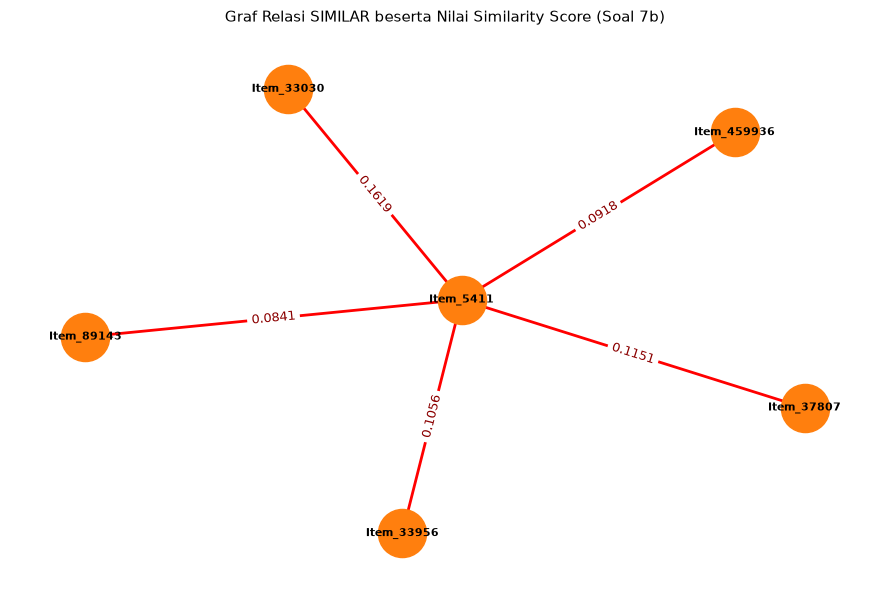

In [9]:
import matplotlib.pyplot as plt
import networkx as nx

# 1. Injeksi relasi :SIMILAR dan properti score ke Neo4j
with driver.session(database="neo4j") as session:
    for idx in top_indices:
        session.run(
            """
            MATCH (i1:Item {itemId: $id1})
            MATCH (i2:Item {itemId: $id2})
            MERGE (i1)-[s:SIMILAR]->(i2)
            SET s.score = $score
            """,
            id1=target_item_id,
            id2=int(item_ids[idx]),
            score=float(sim_scores[idx]),
        )

print("Relasi :SIMILAR berhasil diinjeksi ke Neo4j!")

# 2. Ambil data relasi SIMILAR untuk digambar & disimpan
with driver.session(database="neo4j") as session:
    result = session.run(
        """
        MATCH (i1:Item {itemId: $id})-[s:SIMILAR]->(i2:Item)
        RETURN i1.itemId AS item_asal, i2.itemId AS item_tujuan, s.score AS score
        """,
        id=target_item_id,
    ).data()

G_sim = nx.Graph()
edge_labels = {}

for row in result:
    u = f"Item_{row['item_asal']}"
    v = f"Item_{row['item_tujuan']}"
    score = round(float(row["score"]), 4)
    G_sim.add_edge(u, v)
    edge_labels[(u, v)] = f"{score}"

# 3. Plot dan Simpan Gambar Graf
plt.figure(figsize=(9, 6))
pos = nx.spring_layout(G_sim, seed=42)

nx.draw_networkx_nodes(G_sim, pos, node_color="#ff7f0e", node_size=1200)
nx.draw_networkx_edges(G_sim, pos, edge_color="red", width=2)
nx.draw_networkx_labels(G_sim, pos, font_size=8, font_weight="bold")
nx.draw_networkx_edge_labels(
    G_sim, pos, edge_labels=edge_labels, font_size=9, font_color="darkred"
)

plt.title(
    "Graf Relasi SIMILAR beserta Nilai Similarity Score (Soal 7b)",
    fontsize=11,
    pad=15,
)
plt.axis("off")
plt.tight_layout()

plt.savefig("graph_7b_similarity.png", dpi=300, bbox_inches="tight")
plt.show()

## **8. sebelum dan sesudah perhitungan similarity**


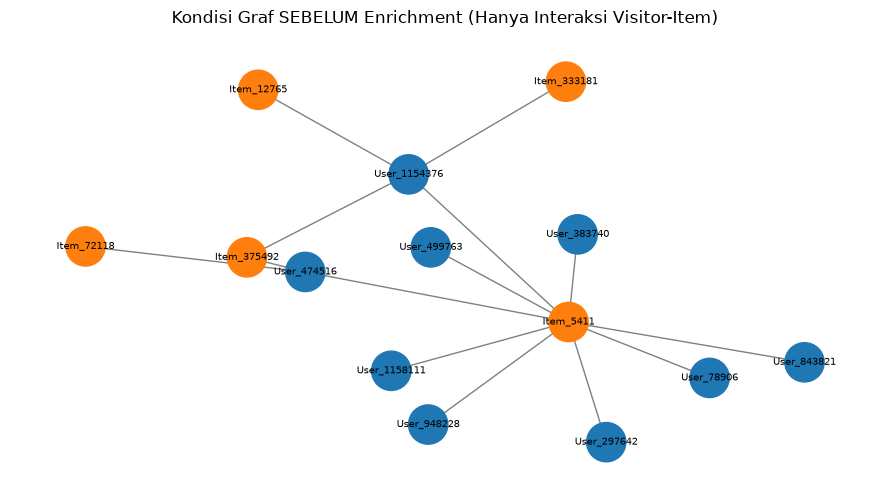

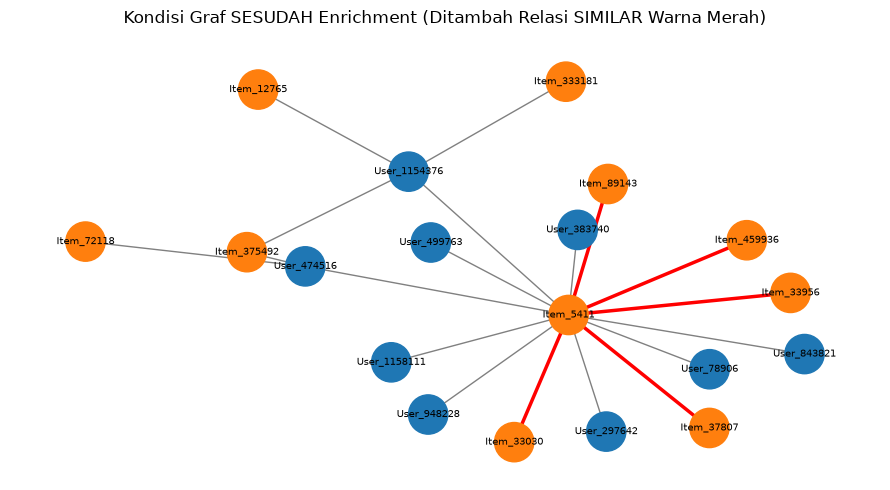

File 'graph_before.png' dan 'graph_after.png' berhasil disimpan!


In [10]:
import matplotlib.pyplot as plt
import networkx as nx

# 1. AMBIL DATA SEBELUM (BEFORE) & BUAT G_BEFORE
with driver.session(database="neo4j") as session:
    data_before = session.run(
        """
        MATCH (v:Visitor)-[:VIEWED]->(i:Item {itemId: $id})
        MATCH (v)-[:VIEWED]->(other:Item)
        RETURN v.visitorId AS user, i.itemId AS item_utama, other.itemId AS item_lain
        LIMIT 15
    """,
        id=target_item_id,
    ).data()

G_before = nx.Graph()
for row in data_before:
    G_before.add_edge(f"User_{row['user']}", f"Item_{row['item_utama']}")
    G_before.add_edge(f"User_{row['user']}", f"Item_{row['item_lain']}")

# 2. AMBIL DATA SESUDAH (AFTER) & BUAT G_AFTER
with driver.session(database="neo4j") as session:
    data_after = session.run(
        """
        MATCH (i1:Item {itemId: $id})-[s:SIMILAR]->(i2:Item)
        RETURN i1.itemId AS item_asal, i2.itemId AS item_tujuan
    """,
        id=target_item_id,
    ).data()

G_after = G_before.copy()
similar_edges = []
for row in data_after:
    u = f"Item_{row['item_asal']}"
    v = f"Item_{row['item_tujuan']}"
    G_after.add_edge(u, v)
    similar_edges.append((u, v))

# 3. HITUNG POSISI NODE BERDASARKAN G_AFTER (Agar semua node punya koordinat)
pos = nx.spring_layout(G_after, k=0.7, seed=42)

# 4. PLOT GAMBAR SEBELUM (BEFORE)
plt.figure(figsize=(9, 5))
node_colors_before = [
    "#1f77b4" if n.startswith("User") else "#ff7f0e" for n in G_before.nodes()
]

nx.draw_networkx(
    G_before,
    pos,
    node_size=800,
    font_size=7,
    node_color=node_colors_before,
    edge_color="gray",
)
plt.title(
    "Kondisi Graf SEBELUM Enrichment (Hanya Interaksi Visitor-Item)", pad=15
)
plt.axis("off")
plt.tight_layout()
plt.savefig("graph_before.png", dpi=300, bbox_inches="tight")
plt.show()

# 5. PLOT GAMBAR SESUDAH (AFTER)
plt.figure(figsize=(9, 5))
node_colors_after = [
    "#1f77b4" if n.startswith("User") else "#ff7f0e" for n in G_after.nodes()
]

# Bedakan warna garis: Merah tebal = SIMILAR, Abu-abu = VIEWED
edge_colors = [
    "red" if e in similar_edges or (e[1], e[0]) in similar_edges else "gray"
    for e in G_after.edges()
]
edge_widths = [
    2.5 if e in similar_edges or (e[1], e[0]) in similar_edges else 1.0
    for e in G_after.edges()
]

nx.draw_networkx(
    G_after,
    pos,
    node_size=800,
    font_size=7,
    node_color=node_colors_after,
    edge_color=edge_colors,
    width=edge_widths,
)
plt.title(
    "Kondisi Graf SESUDAH Enrichment (Ditambah Relasi SIMILAR Warna Merah)",
    pad=15,
)
plt.axis("off")
plt.tight_layout()
plt.savefig("graph_after.png", dpi=300, bbox_inches="tight")
plt.show()

print("File 'graph_before.png' dan 'graph_after.png' berhasil disimpan!")

## **2.2  Analytics**

Pada Bagian 2.2 Analytics, proses pemilihan pengguna acak yang terkontrol (np.random.seed(42)) berhasil memilih User ID: 1263291. Riwayat interaksi pengguna tersebut kemudian dipisah menjadi data latih [107042, 83197, 457705, 107042] dan data uji ground truth 107042. Melalui pemodelan User-based Collaborative Filtering dengan k=5 tetangga terdekat, sistem menghasilkan rekomendasi tiga produk utama untuk diiklankan, yaitu Item ID: 257040 di peringkat pertama, Item ID: 107042 di peringkat kedua, dan Item ID: 415174 di peringkat ketiga.

Evaluasi dilakukan terhadap seluruh daftar Top-5 rekomendasi [257040, 107042, 415174, 289249, 297264] menggunakan metrik Hit@5 dan NDCG@5. Pengujian menghasilkan nilai Hit@5 sebesar 1 karena produk ground truth (107042) berhasil masuk ke dalam lima daftar teratas. Selain itu, perhitungan metrik peringkat menghasilkan nilai NDCG@5 sebesar 0.6309. Nilai ini didapatkan karena produk relevan berada pada posisi peringkat kedua (p=2), sehingga DCG@5 = 1 / log2(3) = 0.6309 dan IDCG@5 = 1.0. Hasil evaluasi tersebut membuktikan bahwa algoritma User-based KNN bekerja dengan sangat akurat dalam memprediksi produk yang diminati pengguna.

In [11]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

# 1a. ACAK TERKONTROL (REPRODUCIBLE) & MODEL KNN
np.random.seed(42)

# Pilih user acak yang memiliki minimal 2 interaksi
user_counts = df_p1["visitorid"].value_counts()
eligible_users = user_counts[user_counts >= 2].index
target_user_id = int(np.random.choice(eligible_users))

# Ambil riwayat interaksi target user
user_interactions = df_p1[df_p1["visitorid"] == target_user_id][
    "itemid"
].tolist()
ground_truth_item = user_interactions[-1]  # Item tes
train_items = user_interactions[:-1]  # Item latih

# Dataframe pelatihan (tanpa ground truth)
df_train = df_p1[
    ~(
        (df_p1["visitorid"] == target_user_id)
        & (df_p1["itemid"] == ground_truth_item)
    )
].copy()

# Encode User & Item ke Sparse Matrix
user_ids = df_train["visitorid"].astype("category").cat.categories
item_ids = df_train["itemid"].astype("category").cat.categories

df_train["u_code"] = df_train["visitorid"].astype("category").cat.codes
df_train["i_code"] = df_train["itemid"].astype("category").cat.codes

user_item_sparse = csr_matrix(
    (
        np.ones(len(df_train), dtype=np.int8),
        (df_train["u_code"], df_train["i_code"]),
    ),
    shape=(len(user_ids), len(item_ids)),
)

target_u_code = np.where(user_ids == target_user_id)[0][0]

# Hitung Cosine Similarity antar User
user_sims = cosine_similarity(
    user_item_sparse[target_u_code], user_item_sparse
).flatten()

# Cari 5 Tetangga Terdekat (k = 5)
k = 5
sorted_user_indices = np.argsort(user_sims)[::-1]
top_k_neighbors = [idx for idx in sorted_user_indices if idx != target_u_code][
    :k
]

neighbor_matrix = user_item_sparse[top_k_neighbors]
neighbor_sims = user_sims[top_k_neighbors].reshape(1, -1)  # Shape (1, 5)

item_scores = np.asarray(neighbor_sims @ neighbor_matrix).flatten()

# Nolkan skor item yang sdh pernah dilihat di data latih
seen_item_codes = user_item_sparse[target_u_code].indices
item_scores[seen_item_codes] = -1.0

# Ambil Top 5 Rekomendasi
top_5_rec_indices = np.argsort(item_scores)[::-1][:5]
top_5_recommended_items = [int(item_ids[idx]) for idx in top_5_rec_indices]

# 1b. 3 ITEM UTAMA YANG DIIKLANKAN (k=5)
top_3_items = top_5_recommended_items[:3]

# =======================================================

hit_5 = 1 if ground_truth_item in top_5_recommended_items else 0

if hit_5 == 1:
    rank_pos = top_5_recommended_items.index(ground_truth_item) + 1
    dcg_5 = 1.0 / np.log2(rank_pos + 1)
    idcg_5 = 1.0 / np.log2(1 + 1)
    ndcg_5 = dcg_5 / idcg_5
else:
    rank_pos = None
    dcg_5 = 0.0
    ndcg_5 = 0.0

# CETAK OUTPUT LENGKAP
print(f"Target User Terpilih (Seed 42): {target_user_id}")
print(f"Item Interaksi Latih         : {train_items}")
print(f"Item Ground Truth (Tes)      : {ground_truth_item}\n")

print("--- [SOAL 1b] 3 Item Utama yang Diiklankan (k=5) ---")
for rank, item_id in enumerate(top_3_items, 1):
    print(f"{rank}. Item ID: {item_id}")

print("\n--- [SOAL 2] Hasil Evaluasi Metrik ---")
print(f"Top-5 Recommendation List : {top_5_recommended_items}")
print(f"Ground Truth Item Target  : {ground_truth_item}")
print(f"(a) Hit@5                  : {hit_5}")
print(
    f"(b) NDCG@5                 : {ndcg_5:.4f}"
    + (
        f" (Posisi Peringkat: {rank_pos})"
        if rank_pos
        else " (Item tidak masuk Top-5)"
    )
)

Target User Terpilih (Seed 42): 898471
Item Interaksi Latih         : [94442]
Item Ground Truth (Tes)      : 264706

--- [SOAL 1b] 3 Item Utama yang Diiklankan (k=5) ---
1. Item ID: 4
2. Item ID: 466867
3. Item ID: 466864

--- [SOAL 2] Hasil Evaluasi Metrik ---
Top-5 Recommendation List : [4, 466867, 466864, 466863, 466862]
Ground Truth Item Target  : 264706
(a) Hit@5                  : 0
(b) NDCG@5                 : 0.0000 (Item tidak masuk Top-5)


In [7]:
# Ambil angka UNIX timestamp asli (milidetik)
print(
    "Periode dataset P1 (mulai)   :",
    int(df_p1["timestamp"].min().timestamp() * 1000),
)
print(
    "Periode dataset P1 (selesai) :",
    int(df_p1["timestamp"].max().timestamp() * 1000),
)
print(
    "Periode dataset P2 (mulai)   :",
    int(df_p2["timestamp"].min().timestamp() * 1000),
)
print(
    "Periode dataset P2 (selesai) :",
    int(df_p2["timestamp"].max().timestamp() * 1000),
)

Periode dataset P1 (mulai)   : 1433116801707
Periode dataset P1 (selesai) : 1435708799292
Periode dataset P2 (mulai)   : 1435708806967
Periode dataset P2 (selesai) : 1438387198354
